# 1. Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../..").resolve()))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from matplotlib.ticker import PercentFormatter

from Src.clustering.plots import build_persistent_cluster_widget, plot_correlation_heatmap
from Src.config import (
    ASSET_DAILY_PATH,
    ASSET_ID_COL,
    ASSETS_PATH,
    CLOSE_COL,
    DATE_COL,
    MARKET_SYMBOL_COL,
    MIN_VOLUME_24H_USD,
    OHLCV_DIR,
    TIMESTAMP_COL,
    VOLUME_COL,
)
from Src.clustering.helpers import HelperFunctions, STABLECOIN_SYMBOLS

helper = HelperFunctions()

print("Imports OK")

Imports OK


# 2. Daten laden & Basket-Konfiguration

In [2]:
# --- Daten laden & vorverarbeiten ---
# Assets-Tabelle: asset_id <-> symbol
assets_df  = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id    = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

# Stablecoin asset_ids berechnen, werden aus der Point Cloud ausgeschlossen
excluded_ids: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)
excluded_syms = sorted(assets_df.loc[assets_df["asset_id"].isin(excluded_ids), "symbol"])
print(f"Ausgeschlossene Stablecoins: {excluded_syms}")

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
print(f"\nOHLCV-Dateien gefunden: {len(ohlcv_files)}")

raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL]      = raw[TIMESTAMP_COL].dt.normalize()

ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

# Rand des verfügbaren Datenbereichs -- wird von mehreren späteren Zellen
# (Kalibrierungs-/Backtest-Split, Lookback-/Persistenz-Suche, Cluster-
# Grösse-Analyse) als Grenze für den Kalibrierungszeitraum gebraucht.
data_min = ohlcv_df[DATE_COL].min().date()
data_max = ohlcv_df[DATE_COL].max().date()

print(f"OHLCV geladen: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Zeitraum: {data_min} → {data_max}")

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
print(f"\nUniverse geladen: {universe_df.shape[0]:,} Zeilen")

Ausgeschlossene Stablecoins: ['PAXG', 'XAUT']

OHLCV-Dateien gefunden: 25


OHLCV geladen: 8,798,178 Zeilen | Assets: 47
Zeitraum: 2024-07-23 → 2026-07-22

Universe geladen: 29,523 Zeilen


In [3]:
# --- Basket-Konfiguration für die Point Cloud ---
# Übernimmt dieselben Grenzen wie 01_baskets.ipynb (BASKET_UPPER_BOUNDS), damit
# beide Notebooks konsistent von denselben 4 Volumen-Baskets ausgehen.
POINTCLOUD_LOOKBACK_DAYS = 7
POINTCLOUD_BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]

rolling_volume_df = helper.compute_rolling_volume_table(
    universe_df,
    id_column=ASSET_ID_COL,
    date_column=DATE_COL,
    volume_column=VOLUME_COL,
    lookback_days=POINTCLOUD_LOOKBACK_DAYS,
)

basket_labels = [f"Basket {n}" for n in range(1, len(POINTCLOUD_BASKET_UPPER_BOUNDS) + 2)]

print("Basket-Definitionen für die Point Cloud:")
for line in helper.describe_volume_baskets(POINTCLOUD_BASKET_UPPER_BOUNDS, MIN_VOLUME_24H_USD):
    print(f"  {line}")

Basket-Definitionen für die Point Cloud:
  Basket 4: $50,000,000 <= volume < $100,000,000
  Basket 3: $100,000,000 <= volume < $250,000,000
  Basket 2: $250,000,000 <= volume < $1,000,000,000
  Basket 1: volume >= $1,000,000,000


# 3. Vietoris-Rips Clustering (Exploratory)

Interaktiver Explorer, ein Tab pro Basket. `HelperFunctions.get_persistent_clusters` folgt jetzt direkt dem PDF-Referenzcode (Abschnitt 5, "Generate trading signal"): *"For simplicity, take the feature with largest persistence"* — `main_feat = max(persistent, key=lambda f: f[2]-f[1])`. Statt giottos H0-Diagramm (dessen Spaltenkonvention im PDF-Beispielcode vertauscht ist — siehe Diskussion) wird direkt auf dem Single-Linkage-Baum gearbeitet, da Vietoris-Rips-H0 mathematisch äquivalent zu Single-Linkage ist:

- Für **jeden** Knoten (= Merge-Event, plus die ursprünglichen Assets als Blätter) gilt: `birth` = Höhe seiner Entstehung, `death` = Höhe, bei der er selbst verschmilzt, gedeckelt bei `epsilon_cap` ("censored death" -- empirisch gegen giotto-tda verifiziert: eine bis `max_edge_length` nie verschmolzene Komponente bekommt dort ebenfalls `death = max_edge_length`, nicht unendlich). `persistence = death - birth`.
- Kandidat ist jeder Knoten mit Grösse >= 2 und `persistence > persistence_threshold`. Singletons zählen nie mit (ein einzelnes, lange isoliertes Asset kann rechnerisch eine hohe, aber bedeutungslose eigene "Persistenz" haben).
- **Von allen Kandidaten gewinnt der mit der höchsten Persistenz.** Die Wurzel (= ganzer Basket als ein Cluster) ist dabei ein ganz normaler Kandidat wie jeder andere Knoten -- keine Sonderrolle, sie gewinnt nur, wenn sie tatsächlich am persistentesten ist.
- Pro Fenster gibt es damit **maximal einen** Cluster (nicht mehrere gleichzeitig wie in einer früheren Version dieses Widgets) -- das entspricht exakt dem PDF-Beispiel.

**epsilon_cap Standard jetzt 1.0** statt sqrt(2) — einer der beiden vom PDF (Abschnitt 6.1 "Parameter Selection") genannten Beispielwerte für `max_edge_length` (0.5 oder 1.0); entspricht bei `d = sqrt(2*(1-rho))` einer Korrelation von `rho = 0.5`.

**Default-Werte pro Basket:** Lookback- und Persistenz-Schwelle-Slider starten mit den in Abschnitt 4 kalibrierten Werten (von Hand als Literale in den Widget-Aufruf übernommen, da diese Zelle vor Abschnitt 4 läuft und dessen Variablen `BEST_LOOKBACK`/`BEST_THRESHOLD` hier noch nicht existieren) -- bei einer erneuten Kalibrierung müssen sie hier manuell nachgezogen werden.

**Bedienung:** Lookback (Tage, +/- Buttons) ist pro Basket-Tab unabhängig einstellbar. Das **Datum ist über alle vier Tabs geteilt** — eine Änderung (Slider, Picker oder +/- Buttons) in irgendeinem Tab aktualisiert automatisch auch die anderen drei. Persistenz-Schwelle und Epsilon-Cap sind pro Tab unabhängig. Ein `render()`-Schutz verhindert redundante Mehrfach-Durchläufe (manche Notebook-Frontends lösen pro Interaktion mehrere "value changed"-Events statt nur eines aus).

Angezeigt werden alle vier Plots als **ein Superplot** (2x2-Grid, eine einzelne Matplotlib-Figure): oben eingefärbtes Dendrogramm und Persistenz-Barcode, darunter Korrelationsmatrix und Distanz-Heatmap (alle mit Zahlen bzw. fixen Achsen [0, 2] = theoretisches Maximum, alle Assets des Baskets immer sichtbar, skaliert horizontal und vertikal sauber mit dem Notebook-Fenster mit -- ein einzelner `plt.show()`-Aufruf für alle vier Panels). Das interaktive Vietoris-Rips-Skelett wurde aus dem Widget entfernt (die Funktion `plot_vietoris_rips_epsilon_slider` bleibt für eigenständige Nutzung in einer separaten Zelle erhalten).

In [4]:
# Default-Werte pro Basket manuell aus Abschnitt 4 übernommen (finale
# Kalibrierung: BEST_LOOKBACK von Hand nach Betrachtung der KORRIGIERTEN
# Jaccard-Kurve gewählt -- t vs. t+lookback, nicht-überlappend, siehe
# Abschnitt 4 -- BEST_THRESHOLD = 90. Perzentil der Persistenz-Verteilung) --
# als Literale statt als Verweis auf BEST_LOOKBACK/BEST_THRESHOLD, weil diese
# Zelle vor Abschnitt 4 ausgeführt wird und die Variablen dort noch nicht
# existieren.
_ = build_persistent_cluster_widget(
    ohlcv_df=ohlcv_df,
    universe_df=universe_df,
    rolling_volume_df=rolling_volume_df,
    id_to_symbol=id_to_symbol,
    id_column=ASSET_ID_COL,
    date_column=DATE_COL,
    basket_labels=basket_labels,
    basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
    excluded_ids=excluded_ids,
    data_min=data_min,
    data_max=data_max,
    default_lookback_days={
        "Basket 1": 7,
        "Basket 2": 10,
        "Basket 3": 15,
        "Basket 4": 5,
    },
    default_persistence_threshold={
        "Basket 1": 0.1916,
        "Basket 2": 0.1085,
        "Basket 3": 0.1272,
        "Basket 4": 0.2570,
    },
    default_epsilon_cap=1.0,
)

# 4. Hyperparameteroptimierung pro Basket

**Wichtige Abgrenzung:** Das zweite PDF ("Additional Information...") beschreibt eine "Second phase: out-of-sample backtest & structural integrity monitoring" -- das ist **nicht** dieser Schritt hier. Diese "Second phase" ist der Live-Überwachungsmechanismus für eine bereits **offene Trading-Position**: sobald ein Cluster gefunden und eine Position eröffnet wurde, wird dessen `death`-Wert (ε*, von `get_persistent_clusters` bereits mitgeliefert) als Referenz gespeichert, und bei jedem folgenden Zeitschritt wird nur für die Assets dieser einen Clique neu `linkage()` gerechnet und bei τ=ε*-δ geschnitten, um zu prüfen, ob die Clique noch zusammenhängt (`len(set(labels_t))==1`) -- die technische Umsetzung der "Cluster break: exit immediately"-Regel aus dem Haupt-PDF (Abschnitt 4.4). Das gehört zum späteren Backtest/Trading-Engine-Teil, nicht zur Hyperparameteroptimierung hier. Hier geht es um die **Kalibrierung der Such-Parameter** (`lookback`, `persistence_threshold`, `epsilon_cap`), mit denen `get_persistent_clusters` überhaupt einen Cluster findet.

**Umsetzung (chronologischer 2-Weg-Split statt 3-Weg — siehe Begründung unten):**

1. **Kalibrierungs-/Backtest-Split** (chronologisch, kein Shuffling): die letzten `BACKTEST_FRACTION` (Standard 20%) der Daten sind der Backtest-Zeitraum und werden hier nicht angefasst. Alles Folgende läuft nur auf dem Kalibrierungszeitraum. Ein einfacher 2-Weg-Split reicht, weil beide folgenden Verfahren **leichtgewichtige, visuelle "Plot ablesen"-Methoden** sind (keine formale Grid-Search mit vielen Vergleichen, die ein eigenes Validation-Set bräuchte, um Overfitting der Auswahl zu vermeiden).

2. **`epsilon_cap` -- ökonomisch begründet, nicht optimiert:** `epsilon_cap=1.0` entspricht bei `d=sqrt(2*(1-rho))` einer Korrelation von `rho=0.5`. Nur Assets mit mindestens moderater positiver Korrelation sollen überhaupt als "verbunden" gelten -- deckt sich mit dem PDF-Beispielwert (0.5 oder 1.0 für `max_edge_length`, Abschnitt 6.1).

3. **`lookback` -- per Jaccard-Stabilitätsplot, aber von Hand gewählt:** Im Gegensatz zu `epsilon_cap` gibt es für den Lookback keine vergleichbare ökonomische Herleitung (das PDF selbst sagt nur "30 Tage üblich, 20-60 experimentieren" -- eine Faustregel, keine Begründung). Für mehrere Kandidaten wird gemessen, wie stabil die Cluster-Zusammensetzung von Tag *t* zu Tag *t+1* ist (Jaccard-Ähnlichkeit der Asset-Mengen, Mittelwert + asymmetrische Std-Fehlerbalken über den Kalibrierungszeitraum -- Mittelwert statt Median, da der Median bei manchen Baskets/Lookbacks exakt auf 1.0 klemmt, wenn die Ähnlichkeit an der Mehrheit der Tage perfekt ist, und dann nicht mehr zwischen Kandidaten unterscheidet), interaktiv geplottet (Plotly, Legende anklickbar zum Ein-/Ausblenden einzelner Baskets). **Kein automatisches Maximum:** die Kurven sind häufig sehr flach mit überlappenden Fehlerbalken -- ein automatisch gewähltes Maximum wäre hier oft nicht robust (siehe auch Mechanik-Vorsicht: längere Lookbacks sind durch Datenüberlappung mechanisch im Vorteil). `BEST_LOOKBACK` wird deshalb bewusst von Hand im Code gesetzt (`DEFAULT_LOOKBACK`, pro Basket überschreibbar), nach Betrachtung des Plots -- das gemessene Maximum wird nur als Referenz mit ausgegeben.

4. **`persistence_threshold` per Histogramm** (PDF Abschnitt 6.1: *"Plot histograms of persistence values to choose a meaningful cutoff"*): mit dem je Basket gewählten Lookback wird die Persistenz **aller** Kandidaten-Knoten (nicht nur des jeweiligen Gewinners, siehe `HelperFunctions.get_all_node_persistences`) über den Kalibrierungszeitraum gesammelt und als Histogramm geplottet; ein hohes Perzentil (Standard 90%, willkürlicher Platzhalter analog zum PDF-Startwert 0.1 -- siehe Diskussion) dient als automatischer Vorschlag, falls keine klare visuelle Lücke erkennbar ist.

5. Die finalen Werte pro Basket landen in `BEST_LOOKBACK` / `BEST_THRESHOLD` (Zusammenfassung am Ende dieses Abschnitts). Der Backtest-Zeitraum wird davon getrennt erst beim eigentlichen Backtest verwendet.

In [5]:
# --- Kalibrierungs-/Backtest-Split (chronologisch, kein Shuffling) ---
# Alles in diesem Abschnitt (Lookback-Suche, Persistenz-Histogramm) arbeitet
# ausschliesslich auf dem Kalibrierungszeitraum. Der Backtest-Zeitraum wird
# erst beim eigentlichen Backtest (später) angefasst.
BACKTEST_FRACTION = 0.2

full_range_days = (data_max - data_min).days + 1
backtest_days = int(full_range_days * BACKTEST_FRACTION)
BACKTEST_START_DATE = data_max - pd.Timedelta(days=backtest_days - 1)
CALIBRATION_END_DATE = BACKTEST_START_DATE - pd.Timedelta(days=1)

print(
    f"Kalibrierungszeitraum: {data_min} bis {CALIBRATION_END_DATE} "
    f"({(CALIBRATION_END_DATE - data_min).days + 1} Tage)"
)
print(
    f"Backtest-Zeitraum (unangetastet bis zum finalen Test): "
    f"{BACKTEST_START_DATE} bis {data_max} ({backtest_days} Tage)"
)

Kalibrierungszeitraum: 2024-07-23 bis 2026-02-26 (584 Tage)
Backtest-Zeitraum (unangetastet bis zum finalen Test): 2026-02-27 bis 2026-07-22 (146 Tage)


In [6]:
# --- Schalter: teure Kalibrierung überspringen ---
# Die Jaccard-Lookback-Suche und die Persistenz-Histogramm-Sammlung (beide
# nächste Zellen) sind mit Abstand die teuersten Zellen im Notebook (mehrere
# Minuten, da für sehr viele Tage/Lookback-Kombinationen jeweils eine
# komplette Point Cloud gebaut wird). Die daraus gewonnenen Werte
# (BEST_LOOKBACK, BEST_THRESHOLD) sind weiter unten als zuletzt bestätigte
# Konstanten hinterlegt -- mit RUN_HYPERPARAMETER_SEARCH=False werden beide
# teuren Zellen übersprungen und direkt diese Werte verwendet.
#
# Auf True setzen, um die Suche neu durchzuführen (z.B. nach neuen Daten,
# geänderten Baskets oder einem längeren Backtest-Zeitraum) -- die Plots
# danach erneut anschauen, um die Werte ggf. von Hand zu bestätigen/anzupassen.
RUN_HYPERPARAMETER_SEARCH = True

# Wird von mehreren Zellen in Abschnitt 4 UND 5 gebraucht (auch wenn die
# teure Suche übersprungen wird) -- deshalb hier einmalig und unconditional
# berechnet statt nur innerhalb der Suche.
all_asset_ids_local = set(universe_df[ASSET_ID_COL].unique())

In [7]:
# --- Lookback-Stabilität: Jaccard-Ähnlichkeit zwischen nicht-überlappenden Fenstern ---
# Vergleicht Tag t gegen Tag t+lookback (NICHT t+1) -- die beiden Fenster
# teilen dann keine Rohdaten, unabhängig vom Lookback-Kandidaten. Ein
# Vergleich gegen t+1 würde bei einem lb-Tage-Lookback (lb-1)/lb der
# Rohdaten teilen und lange Lookbacks dadurch rein mechanisch stabiler
# aussehen lassen, ohne dass die Cluster deshalb tatsächlich besser wären.
#
# LOOKBACK_CANDIDATES bewusst kurz gehalten (0.5 bis 30 Tage).
#
# DAY_STRIDE reduziert die Anzahl geprüfter Start-Tage (der Punktwolken-
# Aufbau ist der teure Teil). t+lookback muss zusätzlich im
# Kalibrierungszeitraum liegen -- bei grossen Lookback-Kandidaten schrumpft
# die nutzbare Stichtagsmenge dadurch entsprechend (informativ, kein
# Fehler). lb=0.5 liefert 0 Vergleiche, weil t+0.5 Tage kein Kalendertag-
# Grenzwert ist -- siehe Normierungs-Hinweis in _cluster_assets_for_day.
LOOKBACK_CANDIDATES = [0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30]
DAY_STRIDE = 5


def _jaccard(a, b):
    a, b = set(a), set(b)
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)


def _cluster_assets_for_day(basket_label, sample_ts, lookback_days):
    # Basket-/Volumen-Zugehörigkeit ist nur auf Tagesgranularität verfügbar
    # (rolling_volume_df hat einen Wert pro Kalendertag) -- deshalb hier
    # explizit normiert, WÄHREND build_point_cloud unten den vollen,
    # nicht normierten sample_ts als Cutoff bekommt (wichtig für
    # sample_ts-Werte, die nicht exakt auf Mitternacht fallen, z.B. bei
    # gebrochenen Lookback-Kandidaten).
    basket_df_at_sample = helper.build_volume_baskets(
        rolling_volume_df, pd.Timestamp(sample_ts).normalize(), id_column=ASSET_ID_COL, date_column=DATE_COL,
        basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
    )
    basket_asset_ids = set(
        basket_df_at_sample.loc[basket_df_at_sample["basket"] == basket_label, ASSET_ID_COL]
    )
    if len(basket_asset_ids) < 2:
        return None

    basket_exclude_ids = excluded_ids | (all_asset_ids_local - basket_asset_ids)
    res = helper.build_point_cloud(
        ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=sample_ts,
        window_size_days=lookback_days, exclude_asset_ids=basket_exclude_ids,
    )
    if res is None or res["n_dimensions"] < 2:
        return None

    dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
    clusters, _ = helper.get_persistent_clusters(
        dist, res["asset_ids"], persistence_threshold=0.0, epsilon_cap=1.0,
    )
    if not clusters:
        return None
    return set(clusters[0]["asset_ids"])


if RUN_HYPERPARAMETER_SEARCH:
    lookback_stability: dict[str, dict[float, list[float]]] = {
        label: {lb: [] for lb in LOOKBACK_CANDIDATES} for label in basket_labels
    }
    CALIBRATION_END_TS = pd.Timestamp(CALIBRATION_END_DATE, tz="UTC")
    DATA_MIN_TS = pd.Timestamp(data_min, tz="UTC")

    for lb in LOOKBACK_CANDIDATES:
        candidate_dates = [
            d for d in pd.date_range(data_min, CALIBRATION_END_DATE, freq="D", tz="UTC")
            if (d - pd.Timedelta(days=lb)) >= DATA_MIN_TS
        ][::DAY_STRIDE]

        n_compared = 0
        for t in candidate_dates:
            t_other = t + pd.Timedelta(days=lb)
            if t_other > CALIBRATION_END_TS:
                continue
            for label in basket_labels:
                assets_t = _cluster_assets_for_day(label, t, lb)
                if assets_t is None:
                    continue
                assets_other = _cluster_assets_for_day(label, t_other, lb)
                if assets_other is not None:
                    lookback_stability[label][lb].append(_jaccard(assets_t, assets_other))
                    n_compared += 1

        print(f"  Lookback={lb}: {len(candidate_dates)} Stichtage, {n_compared} Vergleiche (über alle Baskets)")

    print("Lookback-Stabilität berechnet.")
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Jaccard-Lookback-Suche übersprungen. "
        "BEST_LOOKBACK wird in der nächsten Zelle direkt aus den zuvor kalibrierten "
        "Werten gesetzt, ohne Neuberechnung."
    )

  Lookback=0.5: 117 Stichtage, 435 Vergleiche (über alle Baskets)


  Lookback=1: 117 Stichtage, 430 Vergleiche (über alle Baskets)


  Lookback=2: 117 Stichtage, 423 Vergleiche (über alle Baskets)


  Lookback=3: 117 Stichtage, 421 Vergleiche (über alle Baskets)


  Lookback=5: 116 Stichtage, 413 Vergleiche (über alle Baskets)


  Lookback=7: 116 Stichtage, 418 Vergleiche (über alle Baskets)


  Lookback=10: 115 Stichtage, 406 Vergleiche (über alle Baskets)


  Lookback=15: 114 Stichtage, 400 Vergleiche (über alle Baskets)


  Lookback=20: 113 Stichtage, 387 Vergleiche (über alle Baskets)


  Lookback=30: 111 Stichtage, 371 Vergleiche (über alle Baskets)
Lookback-Stabilität berechnet.


In [8]:
# --- Lookback-Stabilität: Plot (Plotly, Legende anklickbar zum Ein-/Ausblenden) ---
# Jaccard-Ähnlichkeit zwischen zwei nicht-überlappenden Fenstern (t vs.
# t+lookback) pro Basket -- siehe Zelle oben.
#
# Mittelwert (nicht Median -- bei manchen Baskets/Lookbacks ist die Jaccard-
# Ähnlichkeit an so vielen Tagen exakt 1.0, dass der Median selbst darauf
# klemmt), mit ASYMMETRISCHEN Fehlerbalken relativ zum Mittelwert (Std der
# Werte oberhalb nach oben, Std der Werte unterhalb nach unten) -- Jaccard
# ist auf [0, 1] beschränkt und meist schief verteilt.
#
# WICHTIG: bei kleinem DAY_STRIDE sind aufeinanderfolgende Stichtage NICHT
# unabhängig -- die Balken unterschätzen die tatsächliche Unsicherheit daher
# systematisch, hier bewusst nur als grobe visuelle Orientierung gedacht,
# kein strenges Konfidenzintervall.
_LOOKBACK_PLOT_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

if RUN_HYPERPARAMETER_SEARCH:
    def _mean_and_split_std(values):
        if not values:
            return None, 0.0, 0.0
        values = np.asarray(values)
        mean = float(np.mean(values))
        above = values[values > mean]
        below = values[values < mean]
        std_up = float(np.sqrt(np.mean((above - mean) ** 2))) if len(above) else 0.0
        std_down = float(np.sqrt(np.mean((below - mean) ** 2))) if len(below) else 0.0
        return mean, std_up, std_down


    fig = go.Figure()
    for i, label in enumerate(basket_labels):
        color = _LOOKBACK_PLOT_COLORS[i % len(_LOOKBACK_PLOT_COLORS)]
        means, stds_up, stds_down = [], [], []
        for lb in LOOKBACK_CANDIDATES:
            mean, std_up, std_down = _mean_and_split_std(lookback_stability[label][lb])
            means.append(mean)
            stds_up.append(std_up)
            stds_down.append(std_down)

        fig.add_trace(go.Scatter(
            x=LOOKBACK_CANDIDATES, y=means, mode="lines+markers", name=label,
            line={"color": color},
            error_y={"type": "data", "array": stds_up, "arrayminus": stds_down, "visible": True, "thickness": 1},
        ))

    fig.update_layout(
        title=(
            "Lookback-Stabilität pro Basket (Klick auf Legende blendet Basket aus)<br>"
            f"<sub>Kalibrierungszeitraum, Schritt={DAY_STRIDE} Tage -- kein automatisches Maximum, auf Plateau/Knick achten</sub>"
        ),
        xaxis_title="Lookback (Tage)",
        yaxis_title="Jaccard-Ähnlichkeit (t vs. t+lookback)",
        height=550,
    )
    fig.show()
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Plot übersprungen (keine "
        "lookback_stability-Daten berechnet). BEST_LOOKBACK unten ist der "
        "zuletzt manuell bestätigte Wert."
    )

# --- Lookback: von Hand gewählt nach Betrachtung des Plots oben (kein
# automatisches Maximum -- die Kurve fällt für alle Baskets über den ganzen
# Kandidatenbereich hinweg monoton, ohne echtes inneres Maximum; "bester"
# Kandidat ist deshalb nicht einfach der kürzeste getestete Wert, sondern
# der Punkt, an dem der MARGINALE Rückgang pro zusätzlichem Tag spürbar
# abflacht -- das Plateau/der Knick, ab dem ein noch kürzerer Lookback kaum
# noch zusätzliche Stabilität kostet):
#   Basket 1: Knick bei ~7 Tagen (Rückgang 10d->15d nahezu 0, 1d->3d dagegen steil)
#   Basket 2: deutlicher Sprung 5d->7d, danach flacher -- Knick bei ~10 Tagen
#   Basket 3: gleichmässig abflachend, spürbares Plateau erst ab ~15 Tagen
#   Basket 4: kleinster/unruhigster Basket (wenig Assets, mehr Rauschen);
#     lokales Plateau bei 5d≈7d, danach weiter fallend -- kurzer Lookback
#     (5 Tage) gewählt.
BEST_LOOKBACK: dict[str, int] = {
    "Basket 1": 7,
    "Basket 2": 10,
    "Basket 3": 15,
    "Basket 4": 5,
}
print("Manuell gewählter Lookback pro Basket:", BEST_LOOKBACK)

Manuell gewählter Lookback pro Basket: {'Basket 1': 7, 'Basket 2': 10, 'Basket 3': 15, 'Basket 4': 5}


In [9]:
# --- persistence_threshold per Histogramm (PDF Abschnitt 6.1) ---
# Nutzt den je Basket in der Lookback-Suche ermittelten BEST_LOOKBACK. Sammelt
# die Persistenz ALLER Kandidaten-Knoten (nicht nur des jeweiligen Gewinners,
# siehe get_all_node_persistences) über den Kalibrierungszeitraum -- so wird
# die Verteilung "Rauschen vs. echtes Signal" sichtbar, nicht nur ein
# einzelner Wert pro Tag.
#
# Jetzt PRO KADENZ (6h/12h/24h) statt nur täglich: die Stichprobe der
# Persistenzwerte hängt von der Abtastdichte ab (eine feinere Kadenz sieht
# z.B. auch kurzlebige Strukturen, die eine tägliche Abtastung verpasst) --
# der Threshold soll deshalb zu der Kadenz passen, mit der später
# tatsächlich discovert wird, statt einen einzigen täglich-kalibrierten
# Wert für alle drei Kadenzen wiederzuverwenden. Ersetzt die frühere
# Kadenz-Wahl per Churn-/Lebensdauer-Heuristik (siehe Notebook-Historie) --
# die driftete bei allen Baskets ähnlich stark mit der Kadenz und trug die
# Basket-Differenzierung nicht überzeugend; statt einer Vorab-Heuristik
# werden jetzt alle drei Kadenzen als gleichwertige Datensätze erzeugt und
# später per Backtest verglichen (siehe 04_clique_cache.ipynb, 04_backtest/).
CADENCE_CANDIDATES_HOURS = [6, 12, 24]
THRESHOLD_DAY_STRIDE = 3  # Ausduennung in KADENZ-SCHRITTEN, bewusst NICHT auf Tage normiert -- eine feinere Kadenz soll dichter (und damit mehr/andere) Snapshots sehen, nicht dieselbe Tagesspanne nur oefter abtasten

if RUN_HYPERPARAMETER_SEARCH:
    persistence_by_basket: dict[str, dict[int, list[float]]] = {
        label: {h: [] for h in CADENCE_CANDIDATES_HOURS} for label in basket_labels
    }

    for label in basket_labels:
        lb = BEST_LOOKBACK[label]
        first_valid = data_min + pd.Timedelta(days=lb - 1)

        for h in CADENCE_CANDIDATES_HOURS:
            sample_dates = [
                d for d in pd.date_range(data_min, CALIBRATION_END_DATE, freq=f"{h}h", tz="UTC")
                if d.date() >= first_valid
            ][::THRESHOLD_DAY_STRIDE]

            for t in sample_dates:
                basket_df_at_t = helper.build_volume_baskets(
                    rolling_volume_df, t.normalize(), id_column=ASSET_ID_COL, date_column=DATE_COL,
                    basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
                )
                basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
                if len(basket_asset_ids) < 2:
                    continue

                basket_exclude_ids = excluded_ids | (all_asset_ids_local - basket_asset_ids)
                res = helper.build_point_cloud(
                    ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
                    window_size_days=lb, exclude_asset_ids=basket_exclude_ids,
                )
                if res is None or res["n_dimensions"] < 2:
                    continue

                dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
                persistence_by_basket[label][h].extend(
                    HelperFunctions.get_all_node_persistences(dist, epsilon_cap=1.0)
                )

            print(f"{label} @ {h:>2}h: {len(persistence_by_basket[label][h])} Persistenzwerte gesammelt (Lookback={lb} Tage)")
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Persistenz-Sammlung übersprungen. "
        "BEST_THRESHOLD wird in der nächsten Zelle direkt aus den zuvor "
        "kalibrierten Werten gesetzt, ohne Neuberechnung."
    )


Basket 1 @  6h: 5102 Persistenzwerte gesammelt (Lookback=7 Tage)


Basket 1 @ 12h: 2553 Persistenzwerte gesammelt (Lookback=7 Tage)


Basket 1 @ 24h: 1280 Persistenzwerte gesammelt (Lookback=7 Tage)


Basket 2 @  6h: 8070 Persistenzwerte gesammelt (Lookback=10 Tage)


Basket 2 @ 12h: 4021 Persistenzwerte gesammelt (Lookback=10 Tage)


...

Basket 3 @ 12h: 3556 Persistenzwerte gesammelt (Lookback=15 Tage)


Basket 3 @ 24h: 1778 Persistenzwerte gesammelt (Lookback=15 Tage)


Basket 4 @  6h: 2649 Persistenzwerte gesammelt (Lookback=5 Tage)


Basket 4 @ 12h: 1342 Persistenzwerte gesammelt (Lookback=5 Tage)


Basket 4 @ 24h: 662 Persistenzwerte gesammelt (Lookback=5 Tage)


Basket 1 @  6h: 90. Perzentil = 0.1999 -> Vorschlag für persistence_threshold
Basket 1 @ 12h: 90. Perzentil = 0.1982 -> Vorschlag für persistence_threshold
Basket 1 @ 24h: 90. Perzentil = 0.1916 -> Vorschlag für persistence_threshold


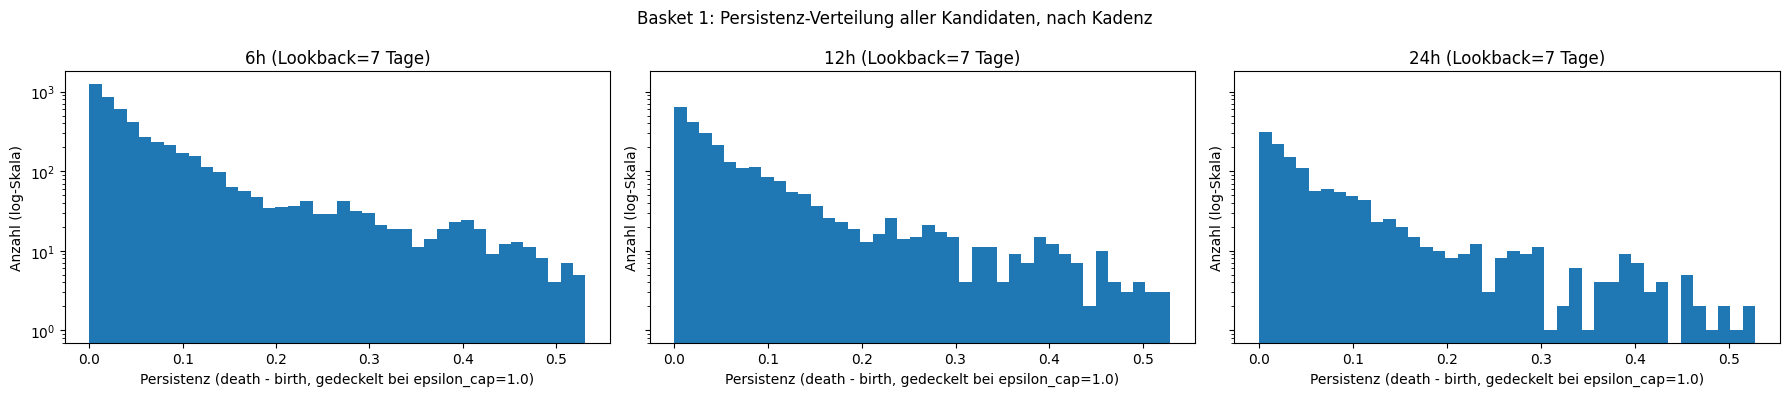

Basket 2 @  6h: 90. Perzentil = 0.1093 -> Vorschlag für persistence_threshold
Basket 2 @ 12h: 90. Perzentil = 0.1091 -> Vorschlag für persistence_threshold
Basket 2 @ 24h: 90. Perzentil = 0.1085 -> Vorschlag für persistence_threshold


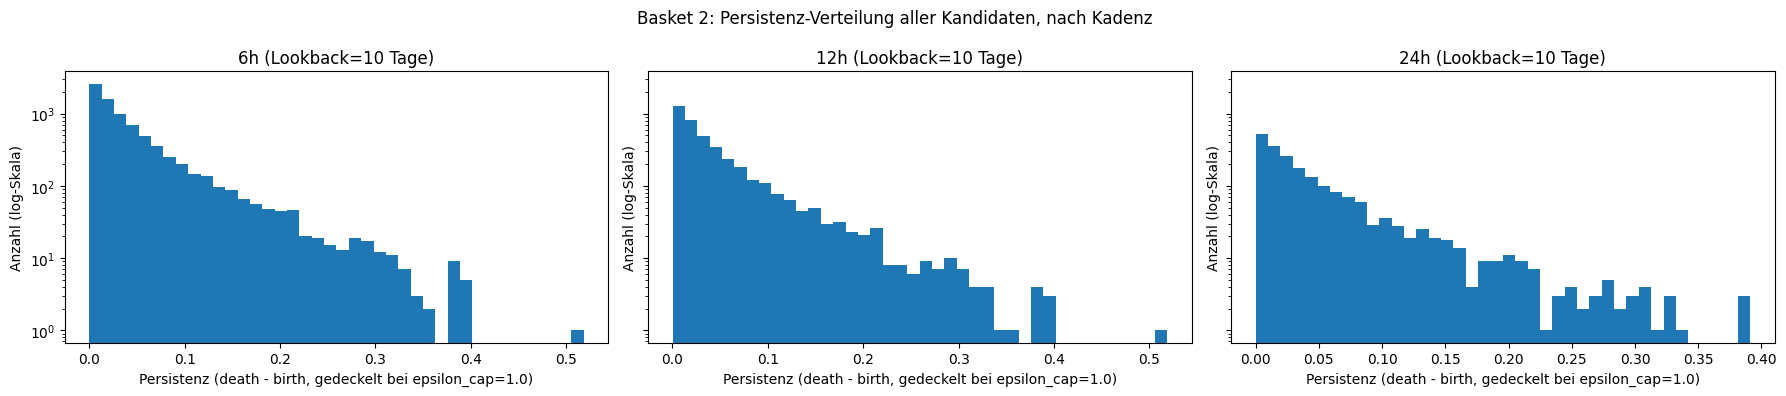

Basket 3 @  6h: 90. Perzentil = 0.1266 -> Vorschlag für persistence_threshold
Basket 3 @ 12h: 90. Perzentil = 0.1273 -> Vorschlag für persistence_threshold
Basket 3 @ 24h: 90. Perzentil = 0.1272 -> Vorschlag für persistence_threshold


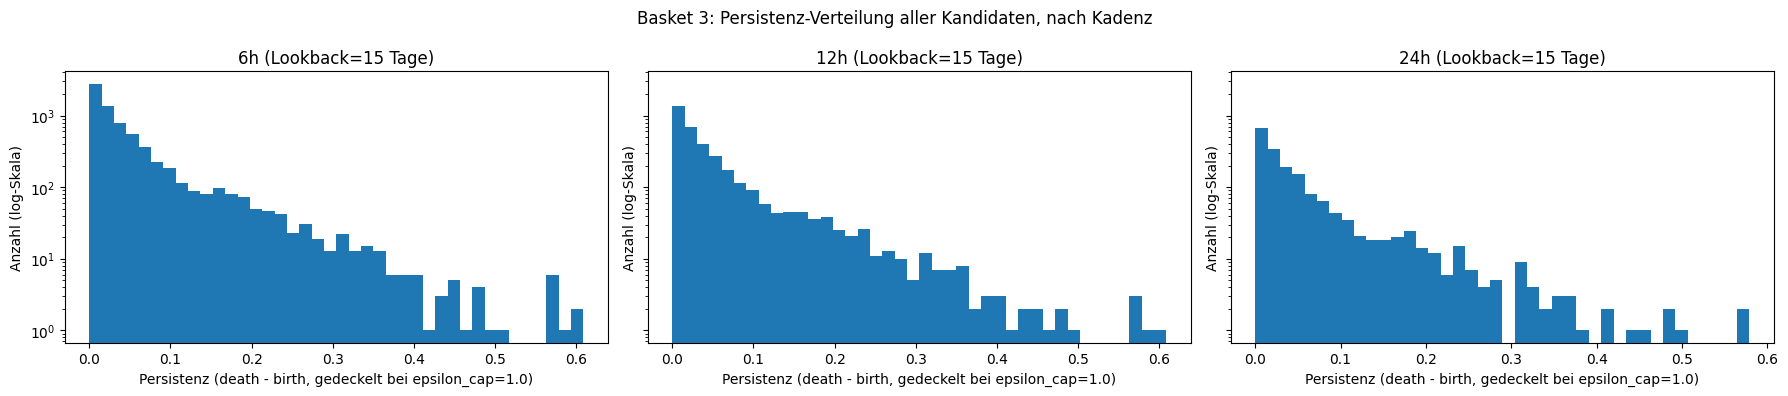

Basket 4 @  6h: 90. Perzentil = 0.2545 -> Vorschlag für persistence_threshold
Basket 4 @ 12h: 90. Perzentil = 0.2545 -> Vorschlag für persistence_threshold
Basket 4 @ 24h: 90. Perzentil = 0.2570 -> Vorschlag für persistence_threshold


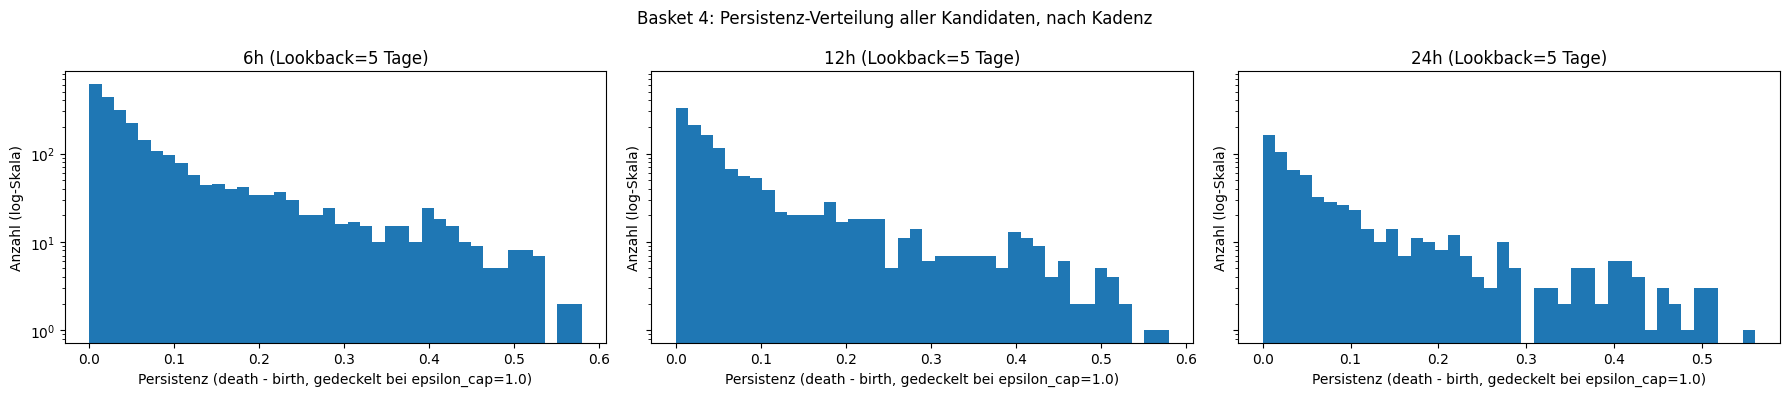

In [10]:
# --- Histogramm + Perzentil-Vorschlag pro (Basket, Kadenz) ---
# SUGGESTED_PERCENTILE ist ein Ersatz, falls keine klare visuelle Lücke
# zwischen "Rauschen nahe 0" und einem längeren Ausläufer erkennbar ist --
# das Histogramm selbst sollte trotzdem angeschaut werden, um das Perzentil
# ggf. von Hand zu korrigieren. Die drei Kadenzen liegen pro Basket als
# Subplots nebeneinander, damit man sie direkt vergleichen kann.
SUGGESTED_PERCENTILE = 90

if RUN_HYPERPARAMETER_SEARCH:
    BEST_THRESHOLD: dict[str, dict[int, float]] = {label: {} for label in basket_labels}
    for label in basket_labels:
        fig, axes = plt.subplots(1, len(CADENCE_CANDIDATES_HOURS), figsize=(6 * len(CADENCE_CANDIDATES_HOURS), 4), sharey=True)
        for ax, h in zip(axes, CADENCE_CANDIDATES_HOURS):
            values = persistence_by_basket[label][h]
            if not values:
                BEST_THRESHOLD[label][h] = 0.1
                print(f"{label} @ {h:>2}h: keine Werte gesammelt, Fallback auf 0.1")
                ax.set_visible(False)
                continue

            ax.hist(values, bins=40)
            ax.set_yscale("log")
            ax.set_xlabel("Persistenz (death - birth, gedeckelt bei epsilon_cap=1.0)")
            ax.set_ylabel("Anzahl (log-Skala)")
            ax.set_title(f"{h}h (Lookback={BEST_LOOKBACK[label]} Tage)")

            pct_value = float(np.percentile(values, SUGGESTED_PERCENTILE))
            BEST_THRESHOLD[label][h] = pct_value
            print(f"{label} @ {h:>2}h: {SUGGESTED_PERCENTILE}. Perzentil = {pct_value:.4f} -> Vorschlag für persistence_threshold")

        fig.suptitle(f"{label}: Persistenz-Verteilung aller Kandidaten, nach Kadenz")
        plt.tight_layout()
        plt.show()
else:
    # Zuletzt bestätigte Werte (90. Perzentil der Persistenz-Verteilung pro
    # (Basket, Kadenz), live aus einem RUN_HYPERPARAMETER_SEARCH=True-Lauf
    # übernommen, siehe Zelle oben für die Stichprobengrössen).
    BEST_THRESHOLD: dict[str, dict[int, float]] = {
        "Basket 1": {6: 0.1999, 12: 0.1982, 24: 0.1916},
        "Basket 2": {6: 0.1093, 12: 0.1091, 24: 0.1085},
        "Basket 3": {6: 0.1266, 12: 0.1273, 24: 0.1272},
        "Basket 4": {6: 0.2545, 12: 0.2545, 24: 0.2570},
    }
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Histogramme übersprungen. "
        "Zuletzt kalibrierter persistence_threshold pro (Basket, Kadenz):", BEST_THRESHOLD,
    )


# 5. Clusteranalyse pro Basket

Nutzt die in Abschnitt 4 kalibrierten Hyperparameter (auch als Default-Werte manuell in das Widget in Abschnitt 3 übernommen, siehe dort). Lookback ist fix pro Basket; der Threshold ist pro (Basket, Kadenz) kalibriert -- alle Auswertungen unten laufen deshalb für jede der drei Kadenz-Kandidaten (6h/12h/24h) separat:

1. **Cluster-Grösse über die Zeit:** mit den kalibrierten Parametern wird -- nur im Kalibrierungszeitraum, für **alle Baskets an denselben Stichtagen innerhalb einer Kadenz** (Voraussetzung für die Überschneidungs-Analyse unten) -- geprüft, wie viele Assets im gefundenen Cluster landen (0, falls an dem Zeitpunkt keiner die Schwelle schafft -- ein informativer Wert, kein fehlender). Interaktiver Plotly-Plot (Legende anklickbar), zusätzlich die jeweilige Basket-Gesamtgrösse als gepunktete Referenzlinie.
2. **Histogramm** der Cluster-Grösse pro Basket, um die Verteilung zu sehen (z.B. Anteil der Zeitpunkte ohne signifikanten Cluster).
3. **Überschneidungen (Zeitpunkte ohne Cluster über mehrere Baskets hinweg):** wie viele Baskets haben an einem Zeitpunkt *gleichzeitig* keinen Cluster (0, 1, 2, 3 oder alle 4)? Verteilung als Balkendiagramm, Verlauf über die Zeit, sowie eine paarweise Heatmap (Anteil gemeinsamer Null-Zeitpunkte je Basket-Paar) -- das zeigt, ob "kein Cluster" eher basketspezifisches Rauschen ist oder eher marktweit gleichzeitig auftritt (z.B. in Phasen, in denen generell alles unkorreliert ist).

**Noch offen:** Stabilität/Übergänge einzelner Asset-Cluster über die Zeit (z.B. wie oft/lange dieselbe Asset-Gruppe bestehen bleibt) sowie sonstige deskriptive Statistiken.


In [11]:
# --- Cluster-Grösse über die Zeit pro Basket, PRO KADENZ (Kalibrierungszeitraum) ---
# Nutzt die je Basket fixen BEST_LOOKBACK sowie den je (Basket, Kadenz)
# kalibrierten BEST_THRESHOLD aus Abschnitt 4. Grösse = Anzahl Assets im
# gefundenen Cluster (0, falls an diesem Zeitpunkt kein Kandidat die
# Schwelle schafft -- ein informativer Wert, kein fehlender).
#
# Wie bisher: alle Baskets nutzen INNERHALB einer Kadenz dieselbe
# Stichtag-Liste (Voraussetzung für die Überschneidungs-Analyse weiter
# unten) -- die Stichtag-Liste selbst unterscheidet sich aber zwischen den
# drei Kadenzen (6h/12h/24h).
CLUSTER_SIZE_STRIDE = 1  # jeder Kadenz-Schritt wird ausgewertet (kein Sampling)

SHARED_FIRST_VALID = data_min + pd.Timedelta(days=max(BEST_LOOKBACK.values()) - 1)
SHARED_SAMPLE_DATES_BY_CADENCE: dict[int, list[pd.Timestamp]] = {
    h: [
        d for d in pd.date_range(data_min, CALIBRATION_END_DATE, freq=f"{h}h", tz="UTC")
        if d.date() >= SHARED_FIRST_VALID
    ][::CLUSTER_SIZE_STRIDE]
    for h in CADENCE_CANDIDATES_HOURS
}

# (Zeitpunkt, Cluster-Grösse, Basket-Gesamtgrösse) je (Kadenz, Basket).
cluster_size_by_cadence: dict[int, dict[str, list[tuple[pd.Timestamp, int, int]]]] = {
    h: {label: [] for label in basket_labels} for h in CADENCE_CANDIDATES_HOURS
}

for h in CADENCE_CANDIDATES_HOURS:
    sample_dates = SHARED_SAMPLE_DATES_BY_CADENCE[h]
    for label in basket_labels:
        lb = BEST_LOOKBACK[label]
        threshold = BEST_THRESHOLD[label][h]

        for t in sample_dates:
            basket_df_at_t = helper.build_volume_baskets(
                rolling_volume_df, t.normalize(), id_column=ASSET_ID_COL, date_column=DATE_COL,
                basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
            )
            basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
            if len(basket_asset_ids) < 2:
                continue

            basket_exclude_ids = excluded_ids | (all_asset_ids_local - basket_asset_ids)
            res = helper.build_point_cloud(
                ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
                window_size_days=lb, exclude_asset_ids=basket_exclude_ids,
            )
            if res is None or res["n_dimensions"] < 2:
                continue

            dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
            clusters, _ = HelperFunctions.get_persistent_clusters(
                dist, res["asset_ids"], persistence_threshold=threshold, epsilon_cap=1.0,
            )
            cluster_size = clusters[0]["size"] if clusters else 0
            cluster_size_by_cadence[h][label].append((t, cluster_size, len(basket_asset_ids)))

        print(f"{label} @ {h:>2}h: {len(cluster_size_by_cadence[h][label])} von {len(sample_dates)} Stichtagen ausgewertet (Lookback={lb}, Schwelle={threshold:.4f})")


Basket 1 @  6h: 2277 von 2277 Stichtagen ausgewertet (Lookback=7, Schwelle=0.1999)


Basket 2 @  6h: 2277 von 2277 Stichtagen ausgewertet (Lookback=10, Schwelle=0.1093)


Basket 3 @  6h: 2237 von 2277 Stichtagen ausgewertet (Lookback=15, Schwelle=0.1266)


Basket 4 @  6h: 1949 von 2277 Stichtagen ausgewertet (Lookback=5, Schwelle=0.2545)


Basket 1 @ 12h: 1139 von 1139 Stichtagen ausgewertet (Lookback=7, Schwelle=0.1982)


...

Basket 4 @ 12h: 975 von 1139 Stichtagen ausgewertet (Lookback=5, Schwelle=0.2545)


Basket 1 @ 24h: 570 von 570 Stichtagen ausgewertet (Lookback=7, Schwelle=0.1916)


Basket 2 @ 24h: 570 von 570 Stichtagen ausgewertet (Lookback=10, Schwelle=0.1085)


Basket 3 @ 24h: 560 von 570 Stichtagen ausgewertet (Lookback=15, Schwelle=0.1272)


Basket 4 @ 24h: 488 von 570 Stichtagen ausgewertet (Lookback=5, Schwelle=0.2570)


In [12]:
# --- Cluster-Grösse über die Zeit: Plot (Plotly, Legende anklickbar), pro Kadenz ---
# Durchgezogen: Cluster-Grösse (0 = kein signifikanter Cluster). Gepunktet,
# halbtransparent: Basket-Gesamtgrösse zum Vergleich.
_BASKET_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for h in CADENCE_CANDIDATES_HOURS:
    fig = go.Figure()
    for i, label in enumerate(basket_labels):
        records = cluster_size_by_cadence[h][label]
        if not records:
            continue
        color = _BASKET_COLORS[i % len(_BASKET_COLORS)]
        dates = [r[0] for r in records]
        sizes = [r[1] for r in records]
        totals = [r[2] for r in records]

        fig.add_trace(go.Scatter(
            x=dates, y=sizes, mode="lines+markers", name=f"{label}: Cluster-Grösse",
            line={"color": color},
        ))
        fig.add_trace(go.Scatter(
            x=dates, y=totals, mode="lines", name=f"{label}: Basket-Grösse (gesamt)",
            line={"color": color, "dash": "dot", "width": 1}, opacity=0.5,
        ))

    fig.update_layout(
        title=(
            f"Cluster-Grösse über die Zeit pro Basket, Kadenz={h}h (Klick auf Legende blendet Serien aus)<br>"
            "<sub>Kalibrierungszeitraum, kalibrierte Hyperparameter (BEST_LOOKBACK/BEST_THRESHOLD[h]) -- 0 = kein Cluster über der Schwelle</sub>"
        ),
        xaxis_title="Zeitpunkt",
        yaxis_title="Anzahl Assets",
        height=550,
    )
    fig.show()


Basket 1 @ 6h: Median=5, Mittelwert=4.15, Anteil ohne Cluster=36.1%
Basket 1 @ 6h (nur Zeitpunkte mit Cluster): Median=6, Mittelwert=6.50
Basket 1 @ 12h: Median=5, Mittelwert=4.18, Anteil ohne Cluster=35.6%
Basket 1 @ 12h (nur Zeitpunkte mit Cluster): Median=6, Mittelwert=6.49
Basket 1 @ 24h: Median=5, Mittelwert=4.29, Anteil ohne Cluster=33.7%
Basket 1 @ 24h (nur Zeitpunkte mit Cluster): Median=6, Mittelwert=6.47


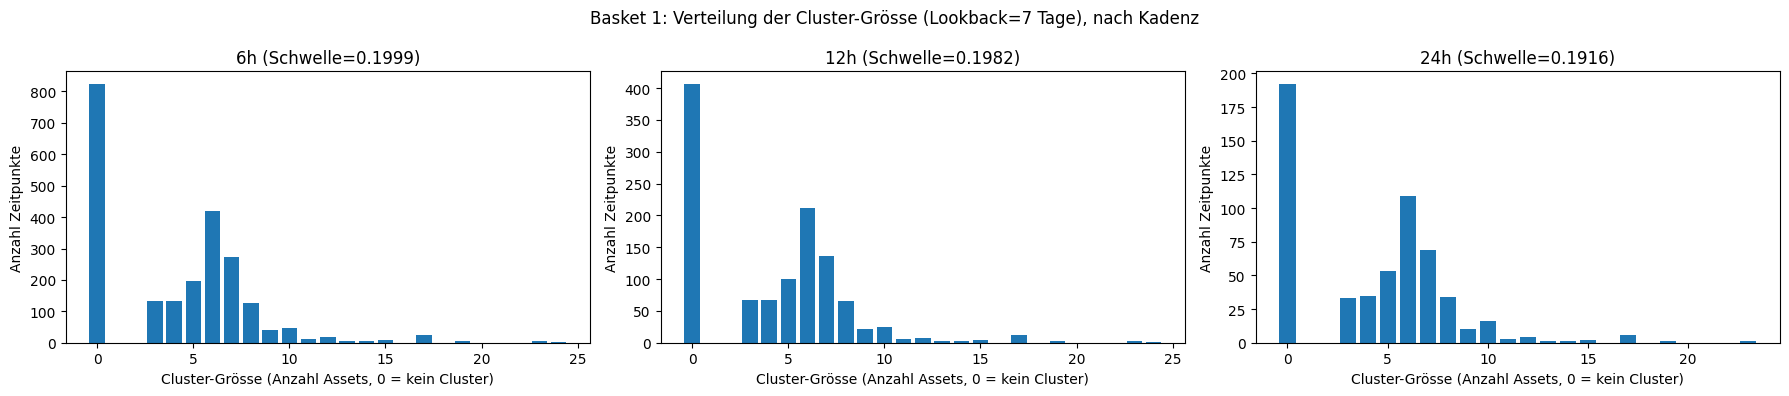

Basket 2 @ 6h: Median=8, Mittelwert=7.99, Anteil ohne Cluster=20.1%
Basket 2 @ 6h (nur Zeitpunkte mit Cluster): Median=9, Mittelwert=9.99
Basket 2 @ 12h: Median=8, Mittelwert=8.00, Anteil ohne Cluster=20.0%
Basket 2 @ 12h (nur Zeitpunkte mit Cluster): Median=9, Mittelwert=10.00
Basket 2 @ 24h: Median=8, Mittelwert=8.03, Anteil ohne Cluster=19.8%
Basket 2 @ 24h (nur Zeitpunkte mit Cluster): Median=9, Mittelwert=10.01


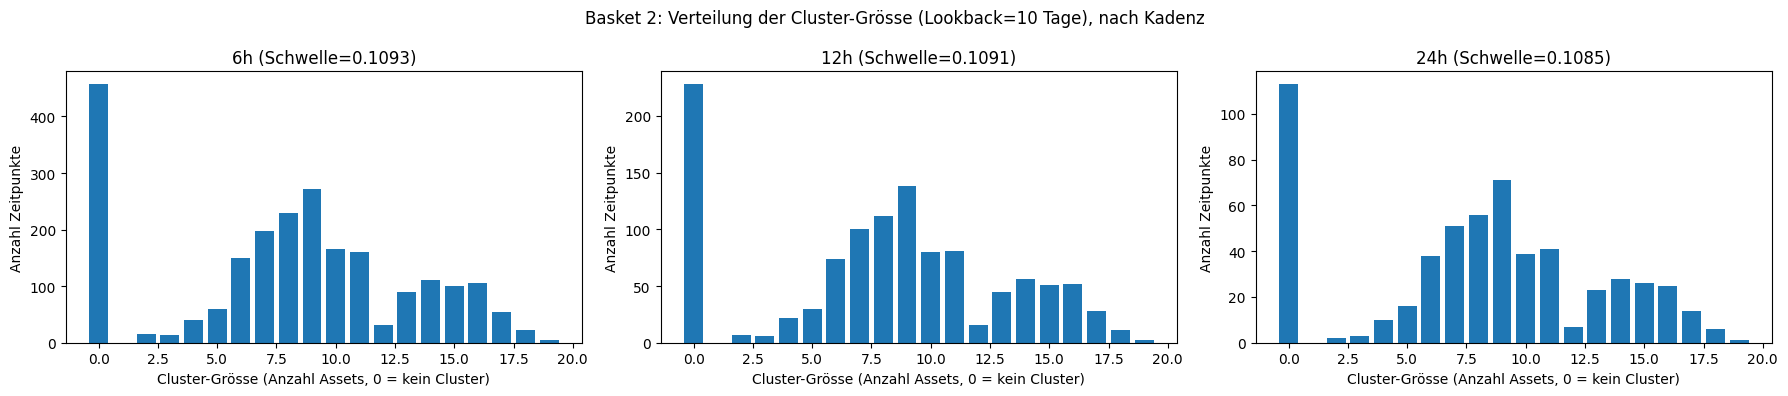

Basket 3 @ 6h: Median=9, Mittelwert=7.69, Anteil ohne Cluster=24.0%
Basket 3 @ 6h (nur Zeitpunkte mit Cluster): Median=10, Mittelwert=10.11
Basket 3 @ 12h: Median=9, Mittelwert=7.68, Anteil ohne Cluster=24.0%
Basket 3 @ 12h (nur Zeitpunkte mit Cluster): Median=10, Mittelwert=10.11
Basket 3 @ 24h: Median=9, Mittelwert=7.66, Anteil ohne Cluster=24.1%
Basket 3 @ 24h (nur Zeitpunkte mit Cluster): Median=10, Mittelwert=10.09


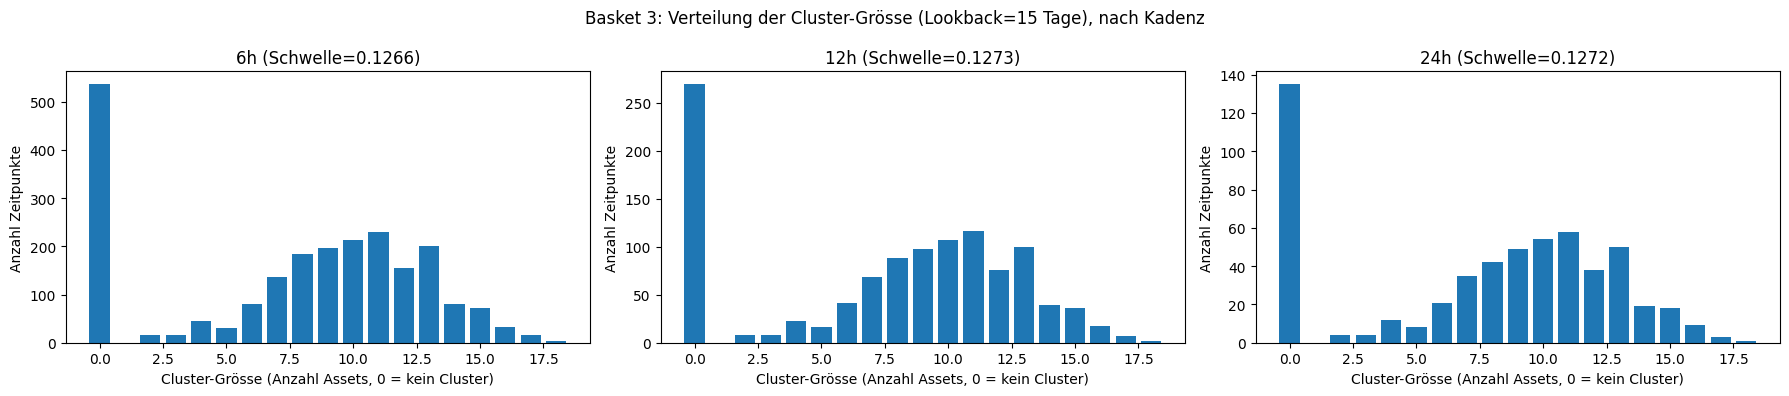

Basket 4 @ 6h: Median=0, Mittelwert=1.83, Anteil ohne Cluster=59.6%
Basket 4 @ 6h (nur Zeitpunkte mit Cluster): Median=4, Mittelwert=4.53
Basket 4 @ 12h: Median=0, Mittelwert=1.83, Anteil ohne Cluster=59.5%
Basket 4 @ 12h (nur Zeitpunkte mit Cluster): Median=4, Mittelwert=4.53
Basket 4 @ 24h: Median=0, Mittelwert=1.79, Anteil ohne Cluster=60.2%
Basket 4 @ 24h (nur Zeitpunkte mit Cluster): Median=4, Mittelwert=4.51


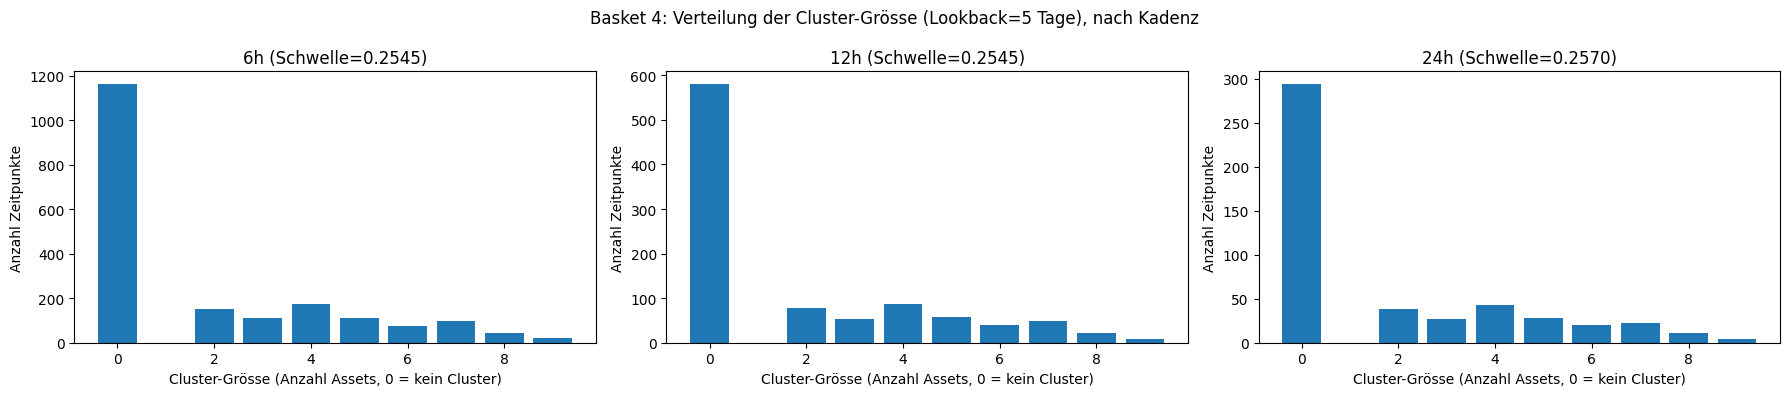

In [13]:
# --- Cluster-Grösse: Histogramm pro Basket, Kadenzen nebeneinander ---
for label in basket_labels:
    fig, axes = plt.subplots(1, len(CADENCE_CANDIDATES_HOURS), figsize=(6 * len(CADENCE_CANDIDATES_HOURS), 4))
    for ax, h in zip(axes, CADENCE_CANDIDATES_HOURS):
        sizes = [r[1] for r in cluster_size_by_cadence[h][label]]
        if not sizes:
            print(f"{label} @ {h}h: keine Werte gesammelt.")
            ax.set_visible(False)
            continue

        max_size = max(sizes)
        ax.hist(sizes, bins=range(max_size + 2), align="left", rwidth=0.8)
        ax.set_xlabel("Cluster-Grösse (Anzahl Assets, 0 = kein Cluster)")
        ax.set_ylabel("Anzahl Zeitpunkte")
        ax.set_title(f"{h}h (Schwelle={BEST_THRESHOLD[label][h]:.4f})")

        sizes_arr = np.asarray(sizes)
        print(
            f"{label} @ {h}h: Median={np.median(sizes_arr):.0f}, Mittelwert={np.mean(sizes_arr):.2f}, "
            f"Anteil ohne Cluster={100 * np.mean(sizes_arr == 0):.1f}%"
        )

        nonzero = sizes_arr[sizes_arr > 0]
        if len(nonzero):
            print(
                f"{label} @ {h}h (nur Zeitpunkte mit Cluster): Median={np.median(nonzero):.0f}, "
                f"Mittelwert={np.mean(nonzero):.2f}"
            )
        else:
            print(f"{label} @ {h}h: an keinem Zeitpunkt ein Cluster gefunden.")

    fig.suptitle(f"{label}: Verteilung der Cluster-Grösse (Lookback={BEST_LOOKBACK[label]} Tage), nach Kadenz")
    plt.tight_layout()
    plt.show()


## Relative Cluster-Grösse (Anteil am Basket)

Absolute Cluster-Grössen sind zwischen den vier Baskets kaum vergleichbar, da die Basket-Grössen stark variieren (Basket 1 hat i.d.R. deutlich mehr Assets als Basket 4). Hier zusätzlich `cluster_size / basket_total` als Anteil pro Tag -- macht die vier Baskets direkt gegenüberstellbar. Nutzt dieselben Rohdaten wie oben (`cluster_size_by_basket`), keine Neuberechnung nötig.

In [14]:
# --- Relative Cluster-Grösse über die Zeit pro Basket (Anteil am Basket), pro Kadenz ---
# Gleiche Rohdaten wie oben (cluster_size_by_cadence), aber cluster_size / basket_total
# statt absoluter Anzahl -- macht die vier (unterschiedlich grossen) Baskets direkt
# vergleichbar: "wie viel Prozent des jeweiligen Baskets bleibt im gefundenen Cluster?"
for h in CADENCE_CANDIDATES_HOURS:
    fig = go.Figure()
    for i, label in enumerate(basket_labels):
        records = cluster_size_by_cadence[h][label]
        if not records:
            continue
        color = _BASKET_COLORS[i % len(_BASKET_COLORS)]
        dates = [r[0] for r in records]
        rel_sizes = [r[1] / r[2] for r in records]

        fig.add_trace(go.Scatter(
            x=dates, y=rel_sizes, mode="lines+markers", name=label,
            line={"color": color},
        ))

    fig.update_layout(
        title=(
            f"Relative Cluster-Grösse über die Zeit pro Basket, Kadenz={h}h (Klick auf Legende blendet Serien aus)<br>"
            "<sub>Kalibrierungszeitraum, kalibrierte Hyperparameter -- Anteil = Cluster-Grösse / Basket-Grösse zu dem Zeitpunkt</sub>"
        ),
        xaxis_title="Zeitpunkt",
        yaxis_title="Anteil des Baskets im Cluster",
        yaxis={"tickformat": ".0%", "range": [0, 1]},
        height=550,
    )
    fig.show()


Basket 1 @ 6h: Median=85.7%, Mittelwert=59.3%, Anteil ohne Cluster=36.1%
Basket 1 @ 6h (nur Zeitpunkte mit Cluster): Median=100.0%, Mittelwert=92.8%
Basket 1 @ 12h: Median=85.7%, Mittelwert=59.7%, Anteil ohne Cluster=35.6%
Basket 1 @ 12h (nur Zeitpunkte mit Cluster): Median=100.0%, Mittelwert=92.8%
Basket 1 @ 24h: Median=85.7%, Mittelwert=61.5%, Anteil ohne Cluster=33.7%
Basket 1 @ 24h (nur Zeitpunkte mit Cluster): Median=100.0%, Mittelwert=92.8%


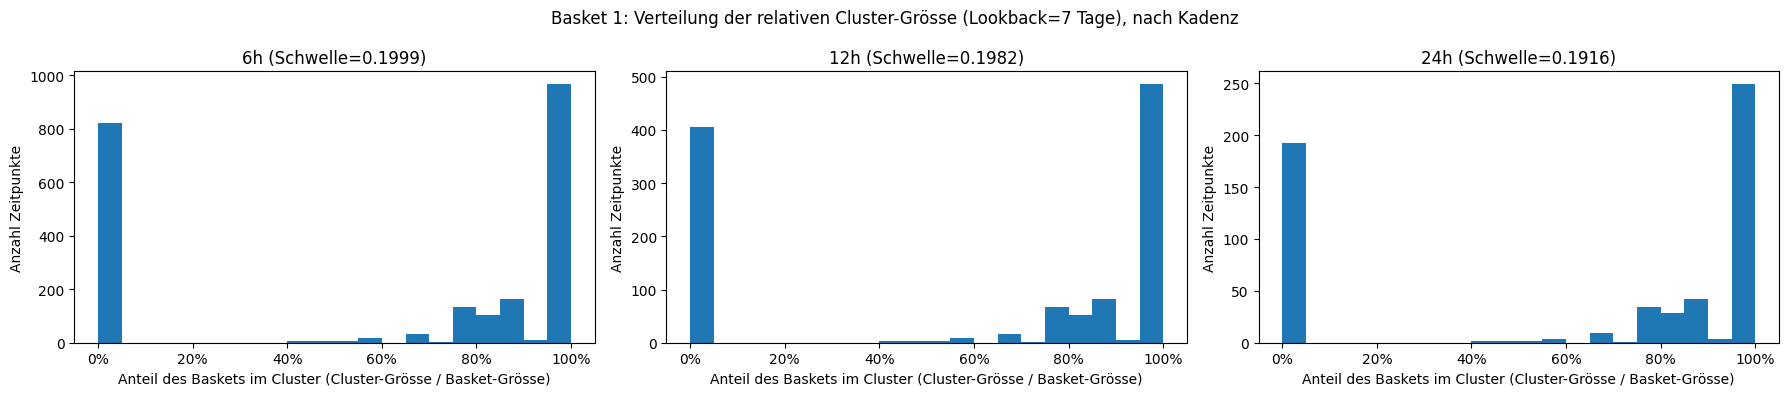

Basket 2 @ 6h: Median=71.4%, Mittelwert=58.0%, Anteil ohne Cluster=20.1%
Basket 2 @ 6h (nur Zeitpunkte mit Cluster): Median=76.2%, Mittelwert=72.6%
Basket 2 @ 12h: Median=71.4%, Mittelwert=58.1%, Anteil ohne Cluster=20.0%
Basket 2 @ 12h (nur Zeitpunkte mit Cluster): Median=76.2%, Mittelwert=72.6%
Basket 2 @ 24h: Median=71.4%, Mittelwert=58.3%, Anteil ohne Cluster=19.8%
Basket 2 @ 24h (nur Zeitpunkte mit Cluster): Median=75.0%, Mittelwert=72.7%


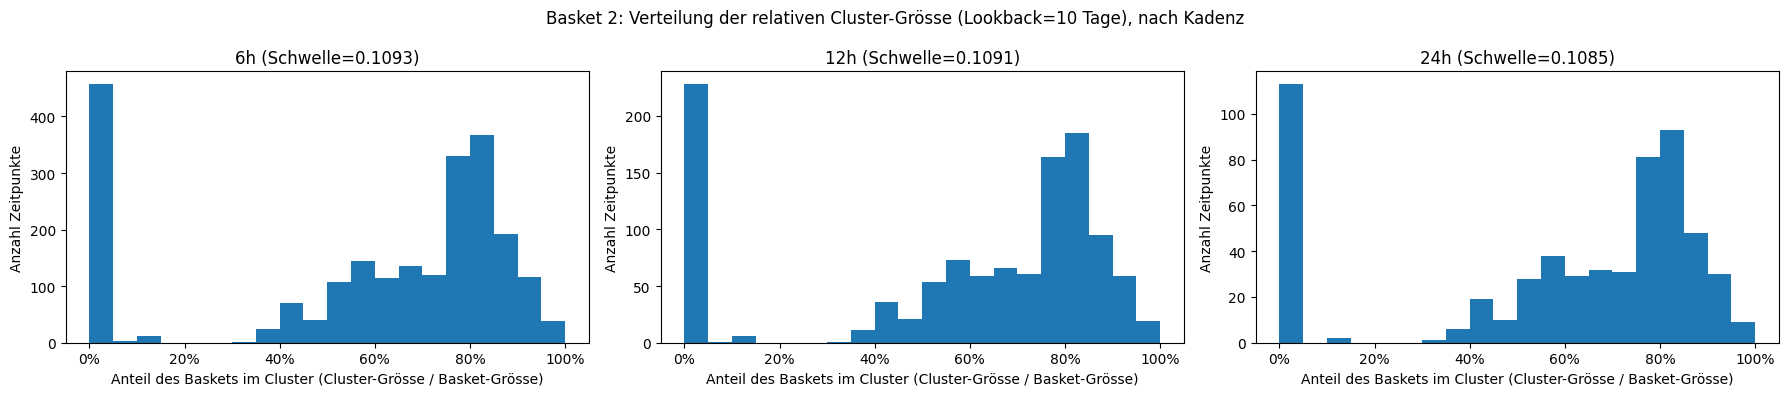

Basket 3 @ 6h: Median=72.7%, Mittelwert=58.8%, Anteil ohne Cluster=24.0%
Basket 3 @ 6h (nur Zeitpunkte mit Cluster): Median=78.6%, Mittelwert=77.3%
Basket 3 @ 12h: Median=72.7%, Mittelwert=58.7%, Anteil ohne Cluster=24.0%
Basket 3 @ 12h (nur Zeitpunkte mit Cluster): Median=78.6%, Mittelwert=77.3%
Basket 3 @ 24h: Median=72.7%, Mittelwert=58.6%, Anteil ohne Cluster=24.1%
Basket 3 @ 24h (nur Zeitpunkte mit Cluster): Median=78.6%, Mittelwert=77.2%


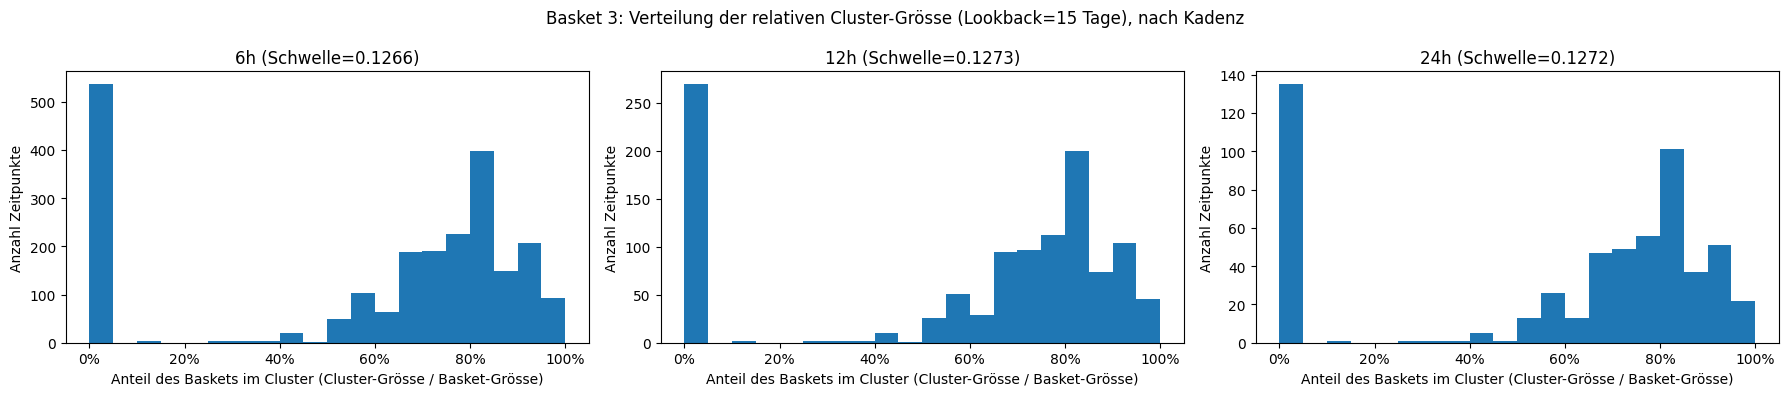

Basket 4 @ 6h: Median=0.0%, Mittelwert=28.5%, Anteil ohne Cluster=59.6%
Basket 4 @ 6h (nur Zeitpunkte mit Cluster): Median=69.2%, Mittelwert=70.5%
Basket 4 @ 12h: Median=0.0%, Mittelwert=28.6%, Anteil ohne Cluster=59.5%
Basket 4 @ 12h (nur Zeitpunkte mit Cluster): Median=69.2%, Mittelwert=70.6%
Basket 4 @ 24h: Median=0.0%, Mittelwert=28.1%, Anteil ohne Cluster=60.2%
Basket 4 @ 24h (nur Zeitpunkte mit Cluster): Median=69.6%, Mittelwert=70.6%


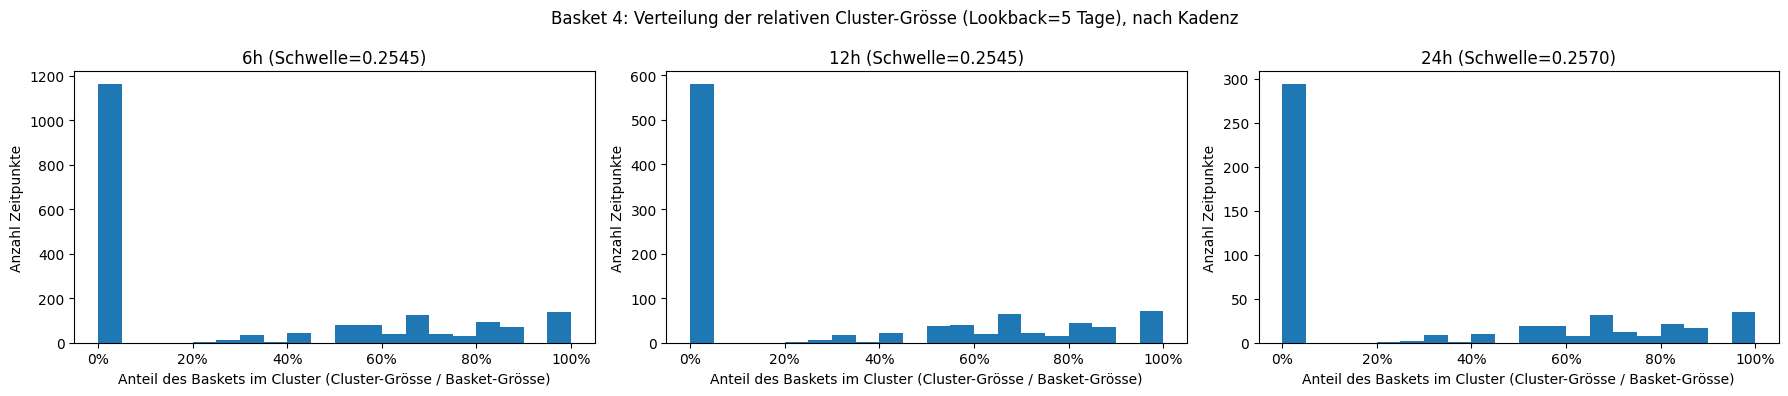

In [15]:
# --- Relative Cluster-Grösse: Histogramm pro Basket, Kadenzen nebeneinander ---
for label in basket_labels:
    fig, axes = plt.subplots(1, len(CADENCE_CANDIDATES_HOURS), figsize=(6 * len(CADENCE_CANDIDATES_HOURS), 4))
    for ax, h in zip(axes, CADENCE_CANDIDATES_HOURS):
        records = cluster_size_by_cadence[h][label]
        rel_sizes = [r[1] / r[2] for r in records]
        if not rel_sizes:
            print(f"{label} @ {h}h: keine Werte gesammelt.")
            ax.set_visible(False)
            continue

        ax.hist(rel_sizes, bins=20, range=(0, 1))
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
        ax.set_xlabel("Anteil des Baskets im Cluster (Cluster-Grösse / Basket-Grösse)")
        ax.set_ylabel("Anzahl Zeitpunkte")
        ax.set_title(f"{h}h (Schwelle={BEST_THRESHOLD[label][h]:.4f})")

        rel_arr = np.asarray(rel_sizes)
        print(
            f"{label} @ {h}h: Median={np.median(rel_arr):.1%}, Mittelwert={np.mean(rel_arr):.1%}, "
            f"Anteil ohne Cluster={100 * np.mean(rel_arr == 0):.1f}%"
        )

        nonzero = rel_arr[rel_arr > 0]
        if len(nonzero):
            print(
                f"{label} @ {h}h (nur Zeitpunkte mit Cluster): Median={np.median(nonzero):.1%}, "
                f"Mittelwert={np.mean(nonzero):.1%}"
            )
        else:
            print(f"{label} @ {h}h: an keinem Zeitpunkt ein Cluster gefunden.")

    fig.suptitle(f"{label}: Verteilung der relativen Cluster-Grösse (Lookback={BEST_LOOKBACK[label]} Tage), nach Kadenz")
    plt.tight_layout()
    plt.show()


## Überschneidungen: Tage ohne Cluster über mehrere Baskets hinweg

Aus `cluster_size_by_basket` (dieselben Stichtage für alle Baskets, siehe oben) wird eine breite Tabelle gebaut: Zeilen = Datum, Spalten = Basket, Werte = Cluster-Grösse (`NaN`, falls der Basket an dem Tag keine gültige Beobachtung hat, z.B. zu wenige Assets -- **nicht** dasselbe wie `0`). Auf dieser Basis: Verteilung der Anzahl gleichzeitig "leerer" Baskets pro Tag, deren Verlauf über die Zeit, und eine paarweise Überschneidungs-Heatmap.

In [16]:
# --- Breite Tabelle (Zeitpunkt x Basket -> Cluster-Grösse) + Null-Cluster-Zählung, pro Kadenz ---
cluster_size_df_by_cadence: dict[int, pd.DataFrame] = {}
n_available_by_cadence: dict[int, pd.Series] = {}
n_zero_by_cadence: dict[int, pd.Series] = {}

for h in CADENCE_CANDIDATES_HOURS:
    _records = [
        {"date": t, "basket": label, "cluster_size": size}
        for label in basket_labels
        for t, size, _total in cluster_size_by_cadence[h][label]
    ]
    df = pd.DataFrame(_records).pivot(index="date", columns="basket", values="cluster_size")
    df = df[basket_labels]  # feste Spaltenreihenfolge Basket 1..4
    cluster_size_df_by_cadence[h] = df

    n_available = df.notna().sum(axis=1)
    n_zero = (df == 0).sum(axis=1)
    n_available_by_cadence[h] = n_available
    n_zero_by_cadence[h] = n_zero

    print(f"--- Kadenz {h}h ---")
    print(f"Zeitpunkte insgesamt: {len(df)}")
    for k in range(len(basket_labels) + 1):
        n_days = int((n_zero == k).sum())
        print(f"  {k} von {len(basket_labels)} Baskets gleichzeitig ohne Cluster: {n_days} Zeitpunkte")

    all_zero_mask = (n_zero == n_available) & (n_available == len(basket_labels))
    all_zero_dates = df.index[all_zero_mask]
    print(f"Zeitpunkte, an denen ALLE {len(basket_labels)} Baskets gleichzeitig 0 Cluster haben: {len(all_zero_dates)}")
    if len(all_zero_dates):
        print("Beispiele:", [d.isoformat() for d in all_zero_dates[:15]])
    print()


--- Kadenz 6h ---
Zeitpunkte insgesamt: 2277
  0 von 4 Baskets gleichzeitig ohne Cluster: 568 Zeitpunkte
  1 von 4 Baskets gleichzeitig ohne Cluster: 864 Zeitpunkte
  2 von 4 Baskets gleichzeitig ohne Cluster: 486 Zeitpunkte
  3 von 4 Baskets gleichzeitig ohne Cluster: 295 Zeitpunkte
  4 von 4 Baskets gleichzeitig ohne Cluster: 64 Zeitpunkte
Zeitpunkte, an denen ALLE 4 Baskets gleichzeitig 0 Cluster haben: 64
Beispiele: ['2024-08-26T00:00:00+00:00', '2024-08-26T06:00:00+00:00', '2024-08-26T12:00:00+00:00', '2024-08-26T18:00:00+00:00', '2024-08-27T00:00:00+00:00', '2024-08-27T06:00:00+00:00', '2024-08-27T12:00:00+00:00', '2024-08-27T18:00:00+00:00', '2024-08-28T00:00:00+00:00', '2024-08-28T06:00:00+00:00', '2024-08-28T12:00:00+00:00', '2024-08-28T18:00:00+00:00', '2024-10-15T06:00:00+00:00', '2024-10-15T12:00:00+00:00', '2024-10-15T18:00:00+00:00']

--- Kadenz 12h ---
Zeitpunkte insgesamt: 1139
  0 von 4 Baskets gleichzeitig ohne Cluster: 287 Zeitpunkte
  1 von 4 Baskets gleichzeitig oh

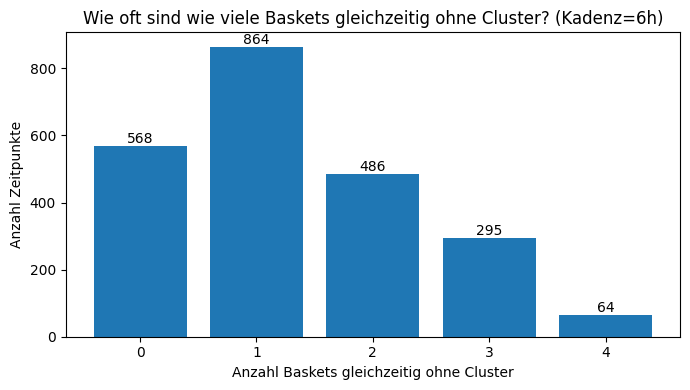

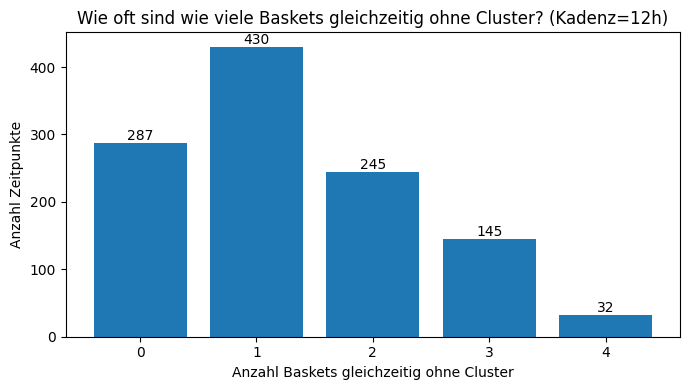

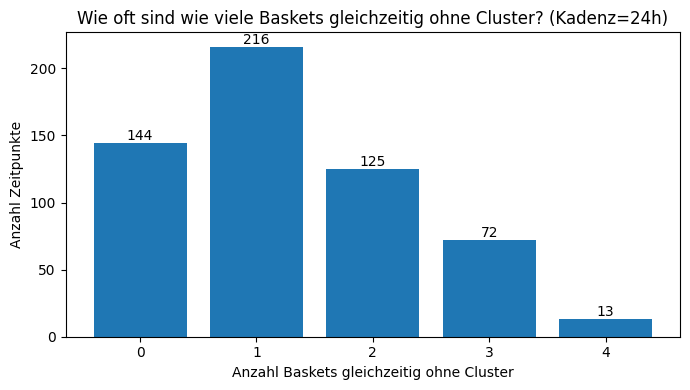

In [17]:
# --- Verteilung: Anzahl gleichzeitig leerer Baskets (Balkendiagramm), pro Kadenz ---
for h in CADENCE_CANDIDATES_HOURS:
    n_zero = n_zero_by_cadence[h]
    counts = [int((n_zero == k).sum()) for k in range(len(basket_labels) + 1)]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(range(len(basket_labels) + 1), counts)
    ax.set_xticks(range(len(basket_labels) + 1))
    ax.set_xlabel("Anzahl Baskets gleichzeitig ohne Cluster")
    ax.set_ylabel("Anzahl Zeitpunkte")
    ax.set_title(f"Wie oft sind wie viele Baskets gleichzeitig ohne Cluster? (Kadenz={h}h)")
    for x, c in enumerate(counts):
        ax.text(x, c, str(c), ha="center", va="bottom")
    plt.tight_layout()
    plt.show()


In [18]:
# --- Verlauf über die Zeit: Anzahl leerer Baskets (Plotly), pro Kadenz ---
# Zeigt, ob "0 Cluster" über die Zeit gleichmässig verteilt ist oder in
# Phasen (z.B. marktweite Unkorreliertheit) gehäuft gleichzeitig auftritt.
for h in CADENCE_CANDIDATES_HOURS:
    n_zero = n_zero_by_cadence[h]
    df = cluster_size_df_by_cadence[h]

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df.index, y=n_zero, mode="lines+markers",
        name="Anzahl Baskets ohne Cluster",
        line={"color": "#d62728"},
    ))
    fig.update_layout(
        title=f"Anzahl gleichzeitig leerer Baskets über die Zeit (Kadenz={h}h, Kalibrierungszeitraum)",
        xaxis_title="Zeitpunkt",
        yaxis_title=f"Anzahl Baskets ohne Cluster (von {len(basket_labels)})",
        yaxis={"range": [-0.3, len(basket_labels) + 0.3], "dtick": 1},
        height=400,
    )
    fig.show()


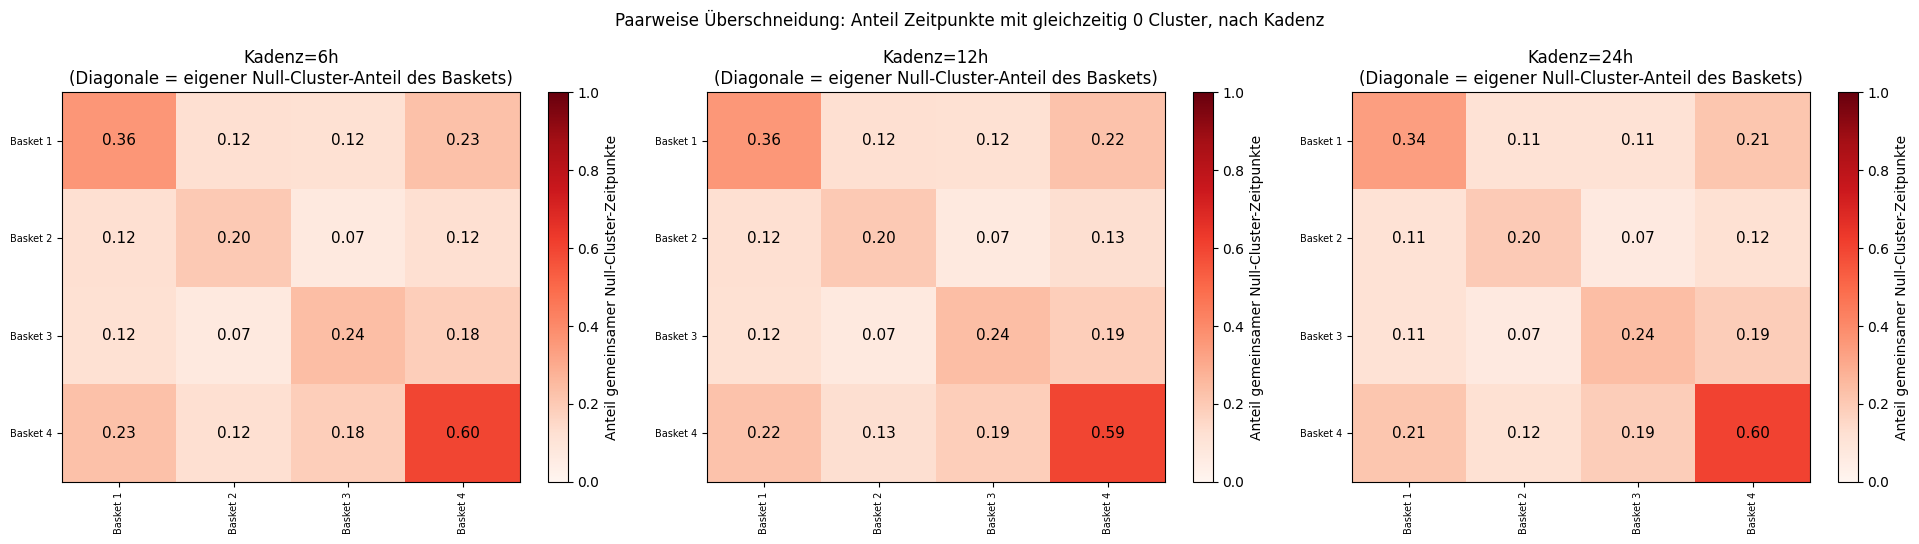

In [19]:
# --- Paarweise Überschneidung: Anteil gemeinsamer Null-Cluster-Zeitpunkte, Kadenzen nebeneinander ---
# Zelle (i, j) = Anteil der Zeitpunkte (unter denen mit gültiger Beobachtung
# für BEIDE Baskets), an denen Basket i UND Basket j gleichzeitig 0 Cluster
# haben. Diagonale = eigener Null-Cluster-Anteil des Baskets.
n_baskets = len(basket_labels)
fig, axes = plt.subplots(1, len(CADENCE_CANDIDATES_HOURS), figsize=(6.5 * len(CADENCE_CANDIDATES_HOURS), 5.5))
for ax, h in zip(axes, CADENCE_CANDIDATES_HOURS):
    df = cluster_size_df_by_cadence[h]
    overlap_matrix = np.full((n_baskets, n_baskets), np.nan)
    for i, li in enumerate(basket_labels):
        for j, lj in enumerate(basket_labels):
            both_valid = df[li].notna() & df[lj].notna()
            if both_valid.sum() == 0:
                continue
            both_zero = (df[li] == 0) & (df[lj] == 0) & both_valid
            overlap_matrix[i, j] = both_zero.sum() / both_valid.sum()

    plot_correlation_heatmap(
        overlap_matrix, basket_labels,
        value_range=(0, 1.0),
        cmap="Reds",
        colorbar_label="Anteil gemeinsamer Null-Cluster-Zeitpunkte",
        title=f"Kadenz={h}h\n(Diagonale = eigener Null-Cluster-Anteil des Baskets)",
        ax=ax, show=False,
    )

fig.suptitle("Paarweise Überschneidung: Anteil Zeitpunkte mit gleichzeitig 0 Cluster, nach Kadenz")
plt.tight_layout()
plt.show()
